In [1]:
#import some basic classes
import numpy as np
import xarray as xr
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cartopy.util as cutil
import matplotlib.pyplot as plt
from matplotlib import colors as c
import matplotlib as mpl
#import statsmodels.api as sm
from tqdm import tqdm
from scipy import stats
#my own classes
import sys
sys.path.append("/emmy-noether/home/mf671/github/blocktrack/lib")
import blocktoolbox as BT
sys.path.append("/emmy-noether/home/mf671/github/AtmBlockPy/lib")
import BlockTools as BlockTools

In [2]:
def check_zg_pIB(ds,zg="",pIB=""):
  try:
    zg = ds[zg]
    pIB = ds[pIB]
    string = "data read successfully"
  except:
    string = "Error code 2: zg variable and pIB were not found. " +\
    "Hint: use read_main() to load data with right attributes."
    print(ds)
    print(string)
    return 2

  #____CHECK GEOP HEIGHT____
  #ERA5 dataset uses geopotential, not height
  try:
    if zg.values[0,0,0,0] > 10000:
      zg = zg/9.80665
  except:
    if zg.values[0,0,0] > 10000:
      zg = zg/9.80665
      
  #creating arrays
  try:
    dat1 = zg.values[:,0,:,:]
    dat2 = pIB.values[:,0,:,:]
  except:
    dat1 = zg.values
    dat2 = pIB.values
  #preparing horizontal positions
  lats = ds.lat.values
  lons = ds.lon.values

  #adding an element to longitude direction as needed by cartopy stereographic transforms
  if lons[len(lons)-1] != lons[0]:
    lons = np.append(lons,180-10**(-6))#slightly different for avoiding contour bug
    dat1 = cutil.add_cyclic_point(dat1)
    dat2 = cutil.add_cyclic_point(dat2)
  return lons,lats,dat1,dat2


In [3]:
def PlotTracking(ds,
                 output,
                 starting_day="1997-01-01T09:00:00.000000000",
                 pIB_tracked="pIB_tracked", #name of IB matrix variable, may vary from file to file
                 zg="zg", #name of zg500 matrix, may vary from file to file
                 mapcrs = ccrs.PlateCarree(),
                 datacrs = ccrs.PlateCarree(),
                 extent =[-180,180,0,90]):

  lons,lats,dat1,dat2 = check_zg_pIB(ds,"zg",pIB_tracked)
  #print(dat1[0],dat2[0])
  #selecting data from the desired days
  index1 = np.searchsorted(ds['time'],np.datetime64(starting_day))
  index2 = index1 + 15
  print(index1,index2)
  dat1 = dat1[index1:index2,:,:]
  dat2 = dat2[index1:index2,:,:]
  #multiple plots for having both contours and flags over different days
  dat2 = BlockTools.OrderIndexes(dat2)
  min = int(np.amin(dat2)) #store min and max for following calculation
  max = int(np.amax(dat2))
  dat2 = np.ma.masked_equal(dat2,0) #mask array1 when ==0
  print(min,max)
  # define the colormap
  list = ['w','g','c','m','r','y','k','tab:blue','tab:orange','tab:green',\
          'tab:purple','tab:brown','tab:pink','tab:gray','olive','cyan','gold',\
          'lightcoral','deeppink','lightsteelblue','lime','indigo','palegoldenrod','b']
  N = max+1
  cmap = c.ListedColormap(list[:N])
  # define the bins and normalize
  if N > 1:
    bounds = np.linspace(0,N,N+1)
  else:
    bounds = [0,1,2]
  norm = mpl.colors.BoundaryNorm(bounds, N)
  for i in range(0,15):
    ax = plt.subplot(5,3,i+1, projection=mapcrs, aspect = 1.0)
    ax.set_extent(extent, datacrs)
    ax.coastlines()
    ax.set_aspect(2)
    #define ranges
    cs_range = np.arange(4500,6500,50) #usually it works
    #plot contour
    #dat2 is normalized in 0,1
    cs_b = ax.contour(lons, lats,dat1[i,:,:], cs_range,colors="black",linewidths = 0.5 ,transform=datacrs)#sec>    plt.clabel(cs_b, colors ="black", fontsize = 5, inline ="false")
    cb = ax.pcolor(lons,lats,dat2[i,:,:],cmap=cmap,vmin = 0,vmax = N,transform=datacrs)#blocking plot
    # create the colorbar
    #cb = plt.colorbar(cb, spacing='proportional',orientation='horizontal',ticks=bounds)
    #cb.set_label('blocking event label')
    # Make some nice titles for the plot
    plt.title(starting_day[0:8] + starting_day[8:10] + ' + ' + str(i) + ' days',fontsize = 12, loc='left')
  #Export image
  try:
    plt.savefig(output,bbox_inches='tight',dpi=250)
    return 0
  except:
    print("Error code 1: no output file was given or something went wrong with matplotlib")
    return 1

In [4]:
%cd /emmy-noether/home/mf671/DATA/ERA5/gr_tracking
#!cdo selmon,6,7,8 ERA5_northem_2.5x2.5_zg_DAV_tracked_unfilt_daily_1940-2023.nc ERA5_northem_2.5x2.5_zg_DAV_tracked_unfilt_daily_jja_1940-2023.nc
!ls

/emmy-noether/home/mf671/DATA/ERA5/gr_tracking
dictionaries
ERA5_northem_2.5x2.5_zg_DAV_tracked_daily_1940-2023.nc
ERA5_northem_2.5x2.5_zg_DAV_tracked_daily_1960-1963.nc
ERA5_northem_2.5x2.5_zg_DAV_tracked_daily_1990-2023.nc
ERA5_northem_2.5x2.5_zg_DAV_tracked_daily_djf_1940-2023.nc
ERA5_northem_2.5x2.5_zg_DAV_tracked_daily_jja_1940-2023.nc
ERA5_northem_2.5x2.5_zg_DAV_tracked_unfilt_daily_1940-2023.nc
ERA5_northem_2.5x2.5_zg_DAV_tracked_unfilt_daily_1960-1963.nc
ERA5_northem_2.5x2.5_zg_GHA_tracked_daily_1940-2023_95perc.nc
ERA5_northem_2.5x2.5_zg_GHA_tracked_daily_1940-2023_md500.nc
ERA5_northem_2.5x2.5_zg_GHA_tracked_daily_1940-2023.nc
ERA5_northem_2.5x2.5_zg_GHA_tracked_daily_1940-2023_new.nc
ERA5_northem_2.5x2.5_zg_GHA_tracked_daily_1960-1963.nc
ERA5_northem_2.5x2.5_zg_GHA_tracked_unfilt_daily_1940-2023.nc
ERA5_northem_2.5x2.5_zg_GHA_tracked_unfilt_daily_1960-1963.nc
ERA5_northem_2.5x2.5_zg_MIX_tracked_daily_1940-2023.nc
ERA5_northem_2.5x2.5_zg_MIX_tracked_daily_1960-1963.nc
ERA5_no

In [10]:
ds = xr.open_dataset('ERA5_northem_2.5x2.5_zg_GHA_tracked_unfilt_daily_1940-2023.nc')
output = '/emmy-noether/home/mf671/github/greenland_blocking/PLOTS/tracking_15days.png'
ds['time'][0]

<xarray.DataArray 'time' ()> Size: 8B
array('1940-01-01T06:00:00.000000000', dtype='datetime64[ns]')
Coordinates:
    time     datetime64[ns] 8B 1940-01-01T06:00:00

29050 29065


100%|████████████████████████████████████████████████████████████████████| 19/19 [00:00<00:00, 11034.59it/s]

0 19


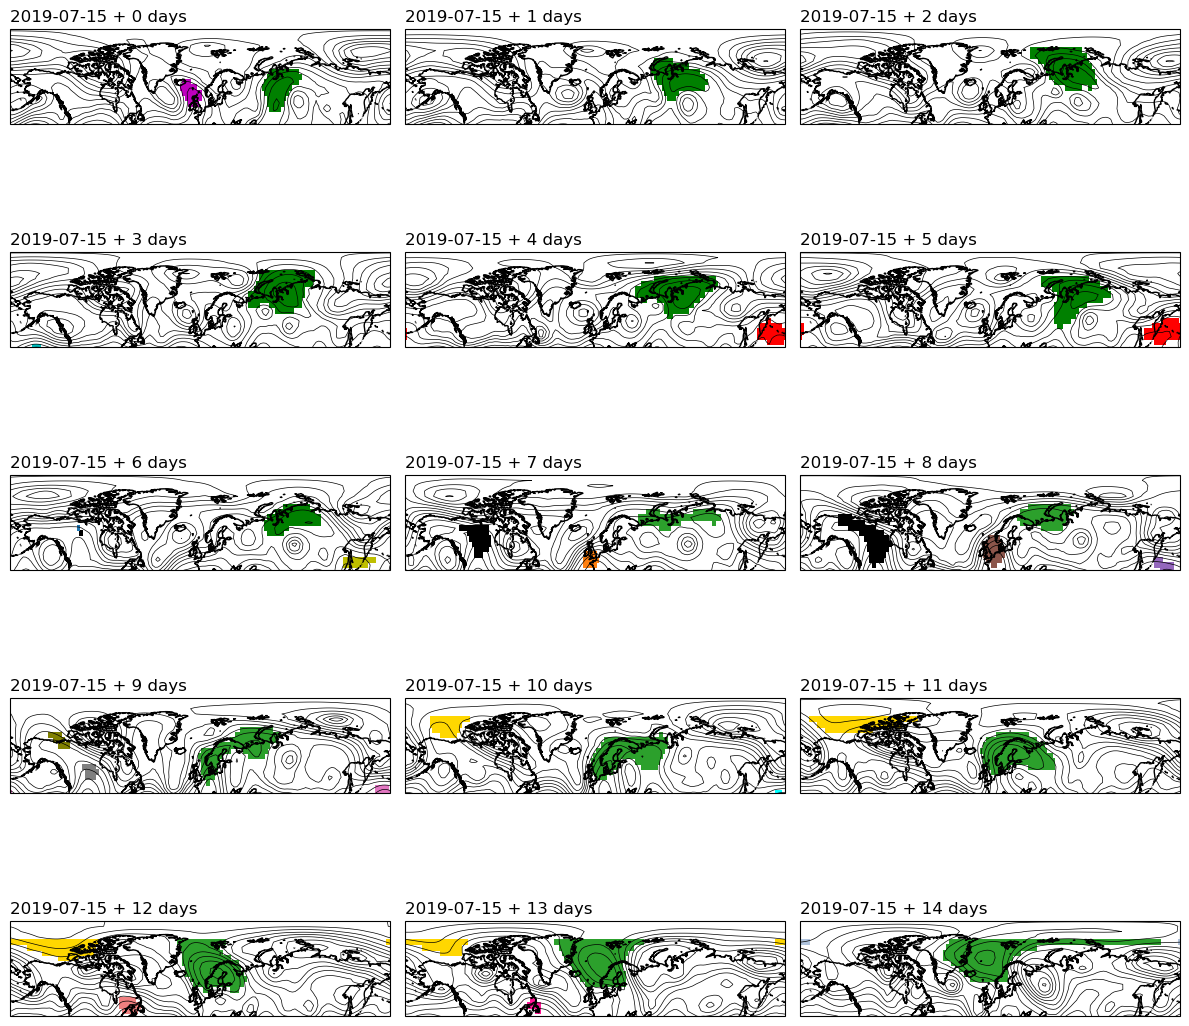

In [11]:
plt.figure(figsize=(12,12))
PlotTracking(ds,
             output,
             starting_day="2019-07-15T06:00:00.000000000",
             pIB_tracked="GHA_tracked", #name of IB matrix variable, may vary from file to file
             zg="zg", #name of zg500 matrix, may vary from file to file
             mapcrs = ccrs.PlateCarree(),
             datacrs = ccrs.PlateCarree(),
             extent =[-180,+180,45,90])
plt.tight_layout()